# Einführung Vega-Lite & Altair

## Vega-Lite

[Vega-Lite](https://vega.github.io/vega-lite/) ist eine High-Level-Grammatik für interaktive Visualisierungen. Sie bietet eine kompakte, deklarative JSON-Syntax zur Erstellung einer großen Anzahl von Visualisierungen für die Datenanalyse und -präsentation.

## Altair

[Altair](https://altair-viz.github.io/) ist eine deklarative statistische Visualisierungsbibliothek für Python, die auf [Vega-Lite](https://vega.github.io/vega-lite/) und [Vega](https://vega.github.io/vega/)  basiert. Der Quellcode ist auf [GitHub](https://github.com/altair-viz/altair) verfügbar.

*Deklarativ* bedeutet, dass auf hoher Ebene angeben werden kann, *was* die Visualisierung enthalten soll, in Form von *Daten*, *grafischen Elementen* und *visuellen Attributen*, anstatt angeben zu müssen, *wie* die Visualisierung in Form von for-Schleifen, Low-Level-Zeichenbefehlen, *etc.* implementiert werden soll. Der Kerngedanke besteht darin, dass Verknüpfungen zwischen Datenfeldern und visuellen Kodierungskanälen, wie z.B. der x-Achse, y-Achse, Farbe usw., deklariert wird. Der Rest der Plotdetails wird automatisch gehandhabt.

### Import

Zu Beginn müssen  die erforderlichen Bibliotheken importiert werden: Pandas für die DataFrames und Altair für die Visualisierung:

In [2]:
#!pip install altair

In [3]:
# notwendigen Bibliotheken importieren:
import pandas as pd
import altair as alt

### Renderer

Je nach Ihrer Umgebung müssen Sie möglicherweise einen [Renderer](https://altair-viz.github.io/user_guide/display_frontends.html) für Altair angeben. Wenn Sie JupyterLab, Jupyter Notebook oder Google Colab mit einer aktiven Internetverbindung verwenden, sollten Sie nichts tun müssen. Andernfalls lesen Sie bitte die [Dokumentation](https://altair-viz.github.io/user_guide/display_frontends.html).

## Daten

Die Daten in Altair sind auf den Pandas-DataFrames aufgebaut, die aus einer Reihe von benannten Datenspalten bestehen. Dabei ist die Benennung der Spalten ein wsentlicher Bestandteil des Plottens mit Altair.

Bei der Verwendung von Altair werden Datensätze in der Regel als DataFrames bereitgestellt. Alternativ kann Altair auch eine URL akzeptieren, um einen Datensatz zu laden, der über das Netzwerk zugänglich ist.

Altair stellt bereits einige Datensätze zu Übungszwecken zur Vefügung: [Vega Datasets](https://github.com/vega/vega-datasets)

In [4]:
#!pip install altair vega_datasets

In [5]:
from vega_datasets import data  # import vega_datasets
cars = data.cars()              # load cars data as a Pandas data frame
cars.head()                     # display the first five rows

,Name,Miles_per_Gallon,Cylinders,Displacement,Horsepower,Weight_in_lbs,Acceleration,Year,Origin
0,chevrolet chevelle malibu,18.0,8,307.0,130.0,3504,12.0,1970-01-01,USA
1,buick skylark 320,15.0,8,350.0,165.0,3693,11.5,1970-01-01,USA
2,plymouth satellite,18.0,8,318.0,150.0,3436,11.0,1970-01-01,USA
3,amc rebel sst,16.0,8,304.0,150.0,3433,12.0,1970-01-01,USA
4,ford torino,17.0,8,302.0,140.0,3449,10.5,1970-01-01,USA


Auf die Datensätze in des Vega-Datasets Repositories kann auch über URLs zugegriffen werden:

In [6]:
data.movies.url

'https://cdn.jsdelivr.net/npm/vega-datasets@v1.29.0/data/movies.json'

Datensatz-URLs können direkt an Altair übergeben werden (für unterstützte Formate wie JSON und CSV oder wie folgt in einen Pandas-DataFrame geladen werden:

In [7]:
movies = pd.read_json(data.movies.url) # load JSON data into a data frame
movies.head()

,Title,US_Gross,Worldwide_Gross,US_DVD_Sales,Production_Budget,Release_Date,MPAA_Rating,Running_Time_min,Distributor,Source,Major_Genre,Creative_Type,Director,Rotten_Tomatoes_Rating,IMDB_Rating,IMDB_Votes
0,The Land Girls,146083.0,146083.0,NaN,8000000.0,Jun 12 1998,R,NaN,Gramercy,NaN,NaN,NaN,NaN,NaN,6.1,1071.0
1,"First Love, Last Rites",10876.0,10876.0,NaN,300000.0,Aug 07 1998,R,NaN,Strand,NaN,Drama,NaN,NaN,NaN,6.9,207.0
2,I Married a Strange Person,203134.0,203134.0,NaN,250000.0,Aug 28 1998,NaN,NaN,Lionsgate,NaN,Comedy,NaN,NaN,NaN,6.8,865.0
3,Let's Talk About Sex,373615.0,373615.0,NaN,300000.0,Sep 11 1998,NaN,NaN,Fine Line,NaN,Comedy,NaN,NaN,13.0,NaN,NaN
4,Slam,1009819.0,1087521.0,NaN,1000000.0,Oct 09 1998,R,NaN,Trimark,Original Screenplay,Drama,Contemporary Fiction,NaN,62.0,3.4,165.0


#### Tidy Dataset
Die statistische Visualisierung in Altair beginnt mit ["tidy"](http://vita.had.co.nz/papers/tidy-data.html) DataFrames. Hier beginnen wir mit der Erstellung eines einfachen DataFrames (`df`), das die Fläche und die Einwohnerzahl der größten Städte in Österreich enthält:

In [8]:
df = pd.DataFrame({
    'city': ['Linz', 'Linz', 'Linz', 'Wien', 'Wien', 'Wien', 'Graz', 'Graz', 'Graz'],
    'month': ['Apr', 'Aug', 'Dec', 'Apr', 'Aug', 'Dec', 'Apr', 'Aug', 'Dec'],
    'temp': [12.1, 20.3, 2.1, 11.0, 20.8, 1.0, 10.5, 19.5, 0.9]
})

df

,city,month,temp
0,Linz,Apr,12.1
1,Linz,Aug,20.3
2,Linz,Dec,2.1
3,Wien,Apr,11.0
4,Wien,Aug,20.8
5,Wien,Dec,1.0
6,Graz,Apr,10.5
7,Graz,Aug,19.5
8,Graz,Dec,0.9


In [9]:
df_niederschlag = pd.DataFrame({
    'Stadt': ['Linz', 'Wien', 'Graz'],
    'Niederschlag': [50, 60, 99]
})

df_niederschlag

,Stadt,Niederschlag
0,Linz,50
1,Wien,60
2,Graz,99


## Chart Object

Das grundlegende Objekt in Altair ist das `Chart`, dem ein DataFrame übergeben wird:

In [10]:
chart = alt.Chart(df)

Bisher haben wir das Objekt `Chart` definiert und ihm ein einfaches DataFrame übergeben, den wir oben erzeugt haben. Wir haben das Chart noch nicht angewiesen, irgendetwas mit den Daten zu tun.

## Visuelle Elemente (Marks)

Mit einem Chart-Objekt können wir nun festlegen, wie die Daten visualisiert werden sollen. Zuerst geben wir an, welche Art von grafischer *Marke* (**visuelles Element**) wir zur Darstellung der Daten verwenden wollen. Wir können das Attribut `mark` des Chart-Objekts mit der Methode `Chart.mark_*` festlegen.

Zum Beispiel können wir die Daten als Punkt darstellen, indem wir `Chart.mark_point()` verwenden:

In [11]:
chart = alt.Chart(df).mark_point()
chart

alt.Chart(...)

#### 🚀 Übung: Probieren Sie weitere Marks aus

Altair enthält eine Reihe von eingebauten Markierungstypen, darunter:

- `mark_area()` - Filled areas defined by a top-line and a baseline.
- `mark_bar()` -	Rectangular bars.
- `mark_circle()`	- Scatter plot points as filled circles.
- `mark_line()` - Connected line segments.
- `mark_point()` - Scatter plot points with configurable shapes.
- `mark_rect()` - Filled rectangles, useful for heatmaps.
- `mark_rule()` - Vertical or horizontal lines spanning the axis.
- `mark_square()` - Scatter plot points as filled squares.
- `mark_text()` - Scatter plot points represented by text.
- `mark_tick()` - Vertical or horizontal tick marks.

Eine komplette Liste mit Beispielen gibt es hier: [Altair Marks Documentation](https://altair-viz.github.io/user_guide/marks.html).

In [12]:
chart = alt.Chart(df).mark_bar()
chart

alt.Chart(...)

Hier besteht das Rendering aus einem Punkt pro Zeile im Datensatz, die alle übereinander gezeichnet werden, da wir noch keine Positionen für diese Punkte festgelegt haben.

Um die Punkte visuell zu trennen, können wir verschiedene *Kodierungskanäle*, oder kurz *Channels* (** visuelle Attribute**) zu den Eigenschaften *(Spalten)* im Datensatz zuordnen. Wir könnten zum Beispiel die Spalte `city` mit dem visuellen Attribut `y` *kodieren*, der die Position der Punkte auf der y-Achse darstellt. Um visuelle Attribute abzubilden, verwenden Sie die Methode `encode`:

In [13]:
chart = alt.Chart(df).mark_point().encode(
    y='city'
)
chart

alt.Chart(...)

Die Methode `encode()` erstellt eine Schlüssel-Wert-Zuordnung zwischen Kodierungskanälen (wie z.B. `x`, `y`, `color`, `shape`, `size`, etc.) zu den Spalten im Datensatz, auf die über Spaltennamen zugegriffen wird. Für Pandas DataFrames bestimmt Altair automatisch einen geeigneten Datentyp für die zugeordnete Spalte, der in diesem Fall der *nominale* Typ ist, der ungeordnete, kategoriale Werte angibt.

Obwohl wir die Daten nun durch ein Attribut getrennt haben, gibt es immer noch mehrere Punkte, die sich innerhalb jeder Kategorie überschneiden. Wir können diese weiter trennen, indem wir einen `x`-Kodierungskanal hinzufügen, der der Spalte `'temp'` zugeordnet ist:

In [14]:
chart = alt.Chart(df).mark_point().encode(
    x='temp',
    y='city'
)
chart

alt.Chart(...)

Der Datentyp der Spalte `'temp'` wird wieder automatisch von Altair abgeleitet und dieses Mal als *quantitativer* Typ behandelt (d.h. eine reelle Zahl). Wir sehen, dass die Gitterlinien und die entsprechenden Achsentitel ebenfalls automatisch hinzugefügt werden.

Oben haben wir Schlüssel-Wert-Paare mit Schlüsselwortargumenten angegeben (`x='temp'`). Darüber hinaus bietet Altair Konstruktionsmethoden zur Kodierung von Definitionen mit der Syntax `alt.X('temp')`. Diese Alternative ist nützlich, um einer Kodierung mehrere Parameter zu übergeben, wie wir später noch sehen werden:


In [15]:
alt.Chart(df).mark_point().encode(
    alt.X('temp'),
    alt.Y('city')
)

alt.Chart(...)

Die beiden Arten der Angabe von Kodierungen können auch kombiniert genutzt werden: `x='temp', alt.Y('city')` ist auch eine gültige Eingabe für die `encode`-Methode.

In [16]:
alt.Chart(df).mark_point().encode(
    alt.X('temp'),
    y='city'
)

alt.Chart(...)

## Datentransformation: Aggregation

Um eine größere Flexibilität bei der Visualisierung von Daten zu ermöglichen, verfügt Altair über eine eingebaute Syntax für die *Aggregation* von Daten. Wir können zum Beispiel den Durchschnitt aller Werte berechnen, indem wir eine Aggregationsfunktion zusammen mit dem Spaltennamen angeben:

In [17]:
alt.Chart(df).mark_point().encode(
    x='mean(temp)',
    y='city'
)

alt.Chart(...)

In jeder Kategorie der x-Achse sehen wir nun einen einzelnen Punkt, der den Durchschnitt der Werte innerhalb dieser Kategorie widerspiegelt.

Altair unterstützt eine Vielzahl von Aggregationsfunktionen, darunter `count` (Anzahl), `min` (Minimum), `max` (Maximum), `average` (Durchschnitt), `median` (Median) und `stdev` (Standardabweichung).

## Änderung des Elementtyps (Mark Type)

Angenommen, wir möchten unsere aggregierten Werte mit rechteckigen Balken statt mit kreisförmigen Punkten darstellen. Wir können dazu `Chart.mark_point` durch `Chart.mark_bar` ersetzen:

In [18]:
alt.Chart(df).mark_bar().encode(
    x='average(temp)',
    y='city'
)

alt.Chart(...)

Da die nominale Spalte `city` auf die `y`--Achse abgebildet wird, ergibt sich ein horizontales Balkendiagramm. Um ein vertikales Balkendiagramm zu erhalten, können wir einfach `x` und `y` vertauschen:

In [19]:
alt.Chart(df).mark_bar().encode(
    x='city',
    y='average(temp)'
)

alt.Chart(...)

## Anpassen einer Visualisierung

Standardmäßig trifft Altair / Vega-Lite viele Entscheidungen über die Eigenschaften der Visualisierung, aber diese können mit Hilfe von bestimmten Methoden geändert werden, um das Aussehen der Visualisierung anzupassen. Zum Beispiel können wir die Achsentitel mit dem `axis`-Attribut festlegen, wir können die Skalierungseigenschaften mit dem `scale`-Attribut ändern und wir können die Farbe einzelner Elemente festlegen, indem wir das `color`-Schlüsselwort der `Chart.mark_*`-Methoden auf einen beliebigen gültigen [CSS-Farbwert](https://developer.mozilla.org/en-US/docs/Web/CSS/color_value) setzen:


In [20]:
alt.Chart(df).mark_point(color='firebrick').encode(
  alt.X('temp', scale=alt.Scale(type='log'), axis=alt.Axis(title='Log-Scaled Values')),
  alt.Y('city', axis=alt.Axis(title='Category')),
)

alt.Chart(...)

## Ausgabe der JSON-Notation

Als Python-API für Vega-Lite besteht der Hauptzweck von Altair darin, Plot-Spezifikationen in einen JSON-String zu konvertieren, der mit dem Vega-Lite-Schema konform ist. Mit der Methode `Chart.to_json` können wir die JSON-Spezifikation prüfen, die Altair exportiert und an Vega-Lite sendet:

In [21]:
chart = alt.Chart(df).mark_bar().encode(
    x='average(temp)',
    y='city',
)
print(chart.to_json())

{
  "$schema": "https://vega.github.io/schema/vega-lite/v6.4.1.json",
  "config": {
    "view": {
      "continuousHeight": 300,
      "continuousWidth": 300
    }
  },
  "data": {
    "name": "data-7f41ec7df670bb075c53817f719782ac"
  },
  "datasets": {
    "data-7f41ec7df670bb075c53817f719782ac": [
      {
        "city": "Linz",
        "month": "Apr",
        "temp": 12.1
      },
      {
        "city": "Linz",
        "month": "Aug",
        "temp": 20.3
      },
      {
        "city": "Linz",
        "month": "Dec",
        "temp": 2.1
      },
      {
        "city": "Wien",
        "month": "Apr",
        "temp": 11.0
      },
      {
        "city": "Wien",
        "month": "Aug",
        "temp": 20.8
      },
      {
        "city": "Wien",
        "month": "Dec",
        "temp": 1.0
      },
      {
        "city": "Graz",
        "month": "Apr",
        "temp": 10.5
      },
      {
        "city": "Graz",
        "month": "Aug",
        "temp": 19.5
      },
      {
     

#### Speichern als Abbildung
Um Visualisierungen als PNG, im Vektorformat oder als jSON-Spezifikation zu exportieren, kann das Kontextmenü oben rechts verwendet werden:

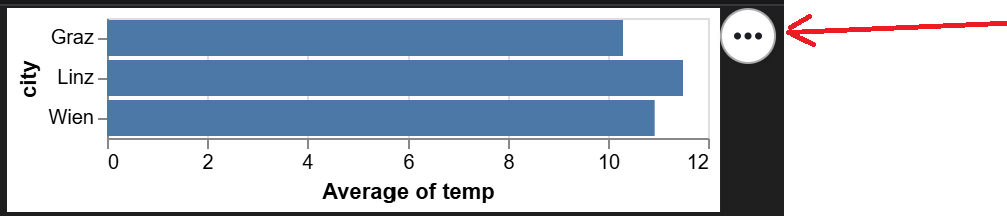

In [22]:
alt.Chart(df).mark_bar().encode(
    y='max(temp)',
    x='city'
)

alt.Chart(...)

## Export einer Visualisierung

Wenn Sie Ihre Daten visualisiert haben, möchten Sie diese vielleicht irgendwo im Internet veröffentlichen. Dies kann ganz einfach mit dem [vega-embed JavaScript package](https://github.com/vega/vega-embed) geschehen. Ein einfaches Beispiel für ein eigenständiges HTML-Dokument kann für jedes Diagramm mit der Methode `Chart.save` erzeugt werden.


```python
chart = alt.Chart(df).mark_bar().encode(
    x='average(temp)',
    y='city',
)
chart.save('chart.html')
```

Diese einfache HTML-Vorlage erzeugt eine Ausgabe, in der die JSON-Spezifikation für die Visualisierung, die von `Chart.to_json` erzeugt wird, in der JavaScript-Variablen `spec` gespeichert werden sollte:

```html
<!DOCTYPE html>
<html>
  <head>
    <script src="https://cdn.jsdelivr.net/npm/vega@5"></script>
    <script src="https://cdn.jsdelivr.net/npm/vega-lite@4"></script>
    <script src="https://cdn.jsdelivr.net/npm/vega-embed@6"></script>
  </head>
  <body>
  <div id="vis"></div>
  <script>
    (function(vegaEmbed) {
      var spec = {}; /* JSON output for your chart's specification */
      var embedOpt = {"mode": "vega-lite"}; /* Options for the embedding */

      function showError(el, error){
          el.innerHTML = ('<div style="color:red;">'
                          + '<p>JavaScript Error: ' + error.message + '</p>'
                          + "<p>This usually means there's a typo in your chart specification. "
                          + "See the javascript console for the full traceback.</p>"
                          + '</div>');
          throw error;
      }
      const el = document.getElementById('vis');
      vegaEmbed("#vis", spec, embedOpt)
        .catch(error => showError(el, error));
    })(vegaEmbed);
  </script>
</body>
</html>
 ```

Die Methode `Chart.save` bietet eine bequeme Möglichkeit, solche HTML-Ausgaben in einer Datei zu speichern. Weitere Informationen zur Einbettung von Altair/Vega-Lite finden Sie in der [Dokumentation des vega-embed Projekts](https://github.com/vega/vega-embed).

##### Credits
The notebook in this collection is based on UW Interactive Data Lab Visualization Curriculum from Jeffrey Heer.